# Step 1: S&P 500 market data with yfinance

Run the cells one by one and check the output after each.
If a cell fails, stop there and send me the error.

## 1.1 Check the libraries

In [4]:
!pip install yfinance pandas


Defaulting to user installation because normal site-packages is not writeable
     -------------------------------------- 149.3/149.3 kB 1.1 MB/s eta 0:00:00
     -------------------------------------- 437.1/437.1 kB 4.5 MB/s eta 0:00:00
     -------------------------------------- 148.0/148.0 kB 4.3 MB/s eta 0:00:00
     -------------------------------------- 144.1/144.1 kB 4.3 MB/s eta 0:00:00
     -------------------------------------- 144.2/144.2 kB 8.4 MB/s eta 0:00:00
     -------------------------------------- 137.8/137.8 kB 2.7 MB/s eta 0:00:00
     -------------------------------------- 137.7/137.7 kB 2.7 MB/s eta 0:00:00
     -------------------------------------- 133.7/133.7 kB 4.0 MB/s eta 0:00:00
     ------------------------------------ 130.8/130.8 kB 429.0 kB/s eta 0:00:00
     -------------------------------------- 130.2/130.2 kB 1.5 MB/s eta 0:00:00
     -------------------------------------- 130.2/130.2 kB 8.0 MB/s eta 0:00:00
     -------------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
anaconda-project 0.11.1 requires ruamel-yaml, which is not installed.
conda-repo-cli 1.0.20 requires clyent==1.2.1, but you have clyent 1.2.2 which is incompatible.
conda-repo-cli 1.0.20 requires nbformat==5.4.0, but you have nbformat 5.5.0 which is incompatible.
conda-repo-cli 1.0.20 requires requests==2.28.1, but you have requests 2.32.5 which is incompatible.


In [5]:
import yfinance as yf
import pandas as pd

print("yfinance", yf.__version__)
print("pandas", pd.__version__)

yfinance 1.2.0
pandas 1.4.4


## 1.2 Test the connection

A small download of a few days. Expected: a table with about 6 rows of Open, High, Low, Close, Adj Close, Volume.
An empty table or a connection error means a network or DNS problem in WSL, not a code problem.

In [7]:
test = yf.download("^GSPC", start="2024-01-01", end="2024-01-10", auto_adjust=False, progress=False)
print("rows:", len(test))
test

rows: 6


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,
2024-01-02,4742.830078,4742.830078,4754.330078,4722.669922,4745.200195,3743050000
2024-01-03,4704.810059,4704.810059,4729.290039,4699.709961,4725.069824,3950760000
2024-01-04,4688.680176,4688.680176,4726.779785,4687.529785,4697.419922,3715480000
2024-01-05,4697.240234,4697.240234,4721.490234,4682.109863,4690.569824,3844370000
2024-01-08,4763.540039,4763.540039,4764.540039,4699.819824,4703.700195,3742320000
2024-01-09,4756.500000,4756.500000,4765.470215,4730.350098,4741.930176,3529960000


## 1.3 Download the full range

The date range matches the Kaggle news dataset. `END` is exclusive in yfinance,
so `2016-07-02` includes 2016-07-01.

In [8]:
TICKER = "^GSPC"
START, END = "2008-08-01", "2016-07-02"

raw = yf.download(TICKER, start=START, end=END, interval="1d", auto_adjust=False, progress=False)
print(raw.shape)
print(type(raw.columns))
raw.head()

(1994, 6)
<class 'pandas.core.indexes.multi.MultiIndex'>


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,
2008-08-01,1260.310059,1260.310059,1270.520020,1254.540039,1269.420044,4684870000
2008-08-04,1249.010010,1249.010010,1260.489990,1247.449951,1253.270020,4562280000
2008-08-05,1284.880005,1284.880005,1284.880005,1254.670044,1254.869995,1219310000
2008-08-06,1289.189941,1289.189941,1291.670044,1276.000000,1283.989990,4873420000
2008-08-07,1266.069946,1266.069946,1286.510010,1264.290039,1286.510010,5319380000


## 1.4 Clean it into a simple table

Newer yfinance versions return two-level column names such as `("Close", "^GSPC")`.
This flattens them to plain names and makes `Date` a normal column.

In [9]:
df = raw.copy()
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df.reset_index()
df["Date"] = pd.to_datetime(df["Date"]).dt.tz_localize(None)
df = df[["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"]]
df = df.sort_values("Date").reset_index(drop=True)
df.head()

Price,Date,Open,High,Low,Close,Adj Close,Volume
0,2008-08-01,1269.420044,1270.520020,1254.540039,1260.310059,1260.310059,4684870000
1,2008-08-04,1253.270020,1260.489990,1247.449951,1249.010010,1249.010010,4562280000
2,2008-08-05,1254.869995,1284.880005,1254.670044,1284.880005,1284.880005,1219310000
3,2008-08-06,1283.989990,1291.670044,1276.000000,1289.189941,1289.189941,4873420000
4,2008-08-07,1286.510010,1286.510010,1264.290039,1266.069946,1266.069946,5319380000


## 1.5 Sanity checks

Expected: about 1,990 rows, first date around 2008-08-01, last date 2016-06-30,
no missing values, and Close values between roughly 680 and 2,130.

In [10]:
print("rows:", len(df))
print("date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("\nmissing values:")
print(df.isna().sum())
print("\nClose min / max:", round(df["Close"].min(), 1), "/", round(df["Close"].max(), 1))
print("duplicate dates:", df["Date"].duplicated().sum())

rows: 1994
date range: 2008-08-01 to 2016-07-01

missing values:
Price
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

Close min / max: 676.5 / 2130.8
duplicate dates: 0


## 1.6 Plot the closing price

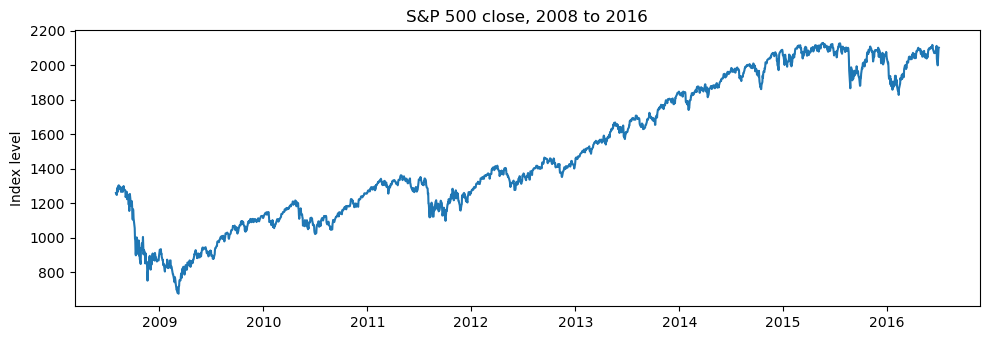

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3.5))
plt.plot(df["Date"], df["Close"])
plt.title("S&P 500 close, 2008 to 2016")
plt.ylabel("Index level")
plt.tight_layout()
plt.show()

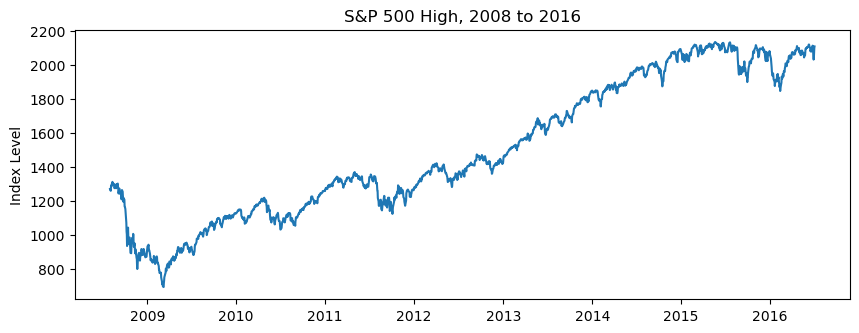

In [12]:
plt.figure(figsize=(10, 3.5))
plt.plot(df["Date"], df["High"])
plt.title("S&P 500 High, 2008 to 2016")
plt.ylabel("Index Level")
plt.show()

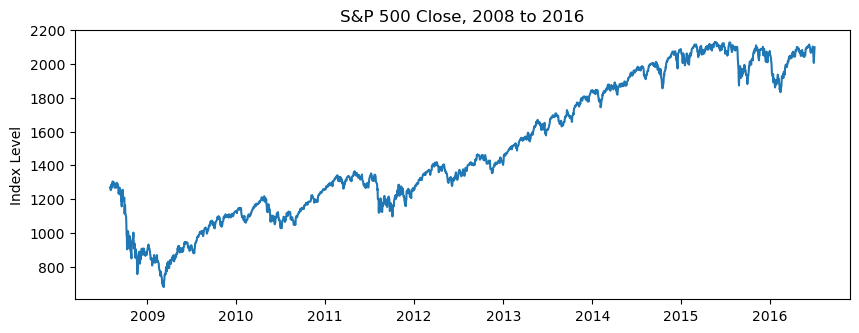

In [13]:
plt.figure(figsize=(10, 3.5))
plt.plot(df["Date"], df["Open"])
plt.title("S&P 500 Close, 2008 to 2016")
plt.ylabel("Index Level")
plt.show()

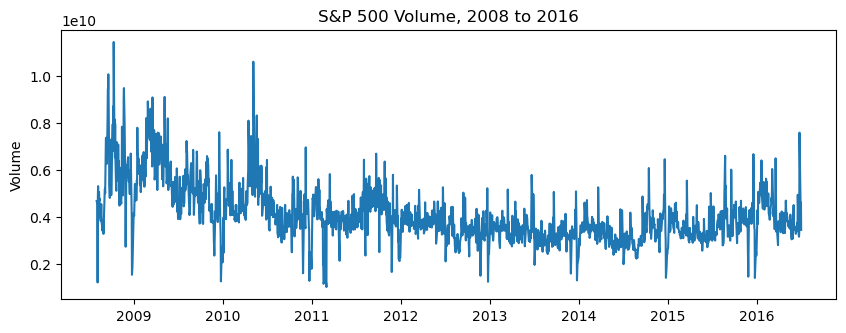

In [14]:
plt.figure(figsize = (10,3.5))
plt.plot(df["Date"], df["Volume"])
plt.title("S&P 500 Volume, 2008 to 2016")
plt.ylabel("Volume")
plt.show()


## 1.7 Save to CSV

Later steps read this file, so the download only has to happen once.

In [15]:
import os

os.makedirs("data", exist_ok=True)
df.to_csv("data/sp500_raw.csv", index=False)
print("saved data/sp500_raw.csv with", len(df), "rows")

saved data/sp500_raw.csv with 1994 rows


**Done with step 1 when** 1.5 shows about 1,990 rows with no missing values and `data/sp500_raw.csv` exists.
Next: step 2, technical features and the Up/Down target.